# ARTI 403 Image Processing
## Lab 6: Frequency Domain

Name: Abdulrahman Saleh Alaamri
ID: 2240002427

The cameraman image comes from skimage (`data.camera()`), I saved a copy in the images folder.

## Task 1: Filtering in the Frequency Domain

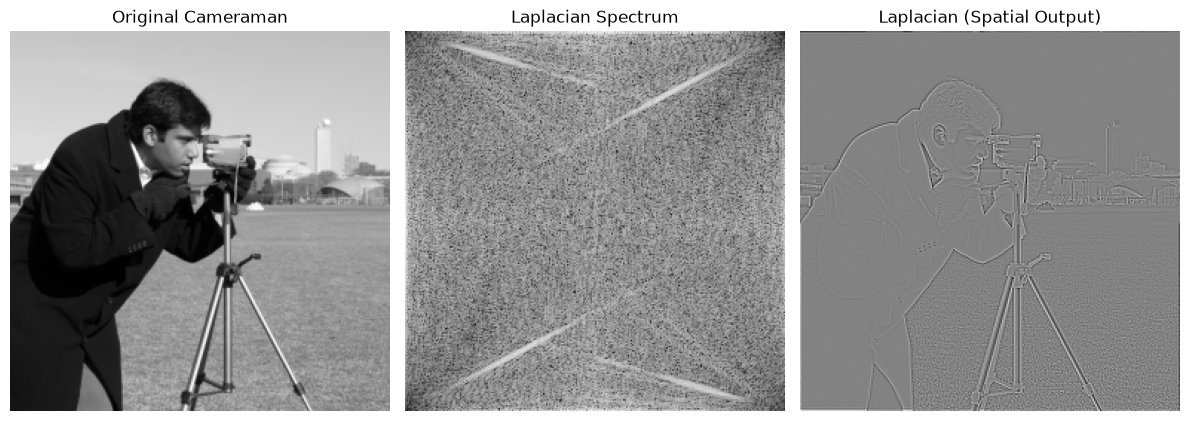

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT

# Get image size
M, N = image.shape

# Generate frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Multiply in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')
plt.tight_layout()
plt.show()

The Laplacian filter is -4π²(u² + v²) in the frequency domain, so it is zero at low frequencies and grows toward high ones. The spectrum is not shifted, so the low frequencies sit in the corners, which are dark. The output only keeps the edges, like the man, the tripod and the buildings, and flat areas like the sky become almost black.

# Assessment

## Task 1
Apply the Sobel filters in the frequency domain on the cameraman image

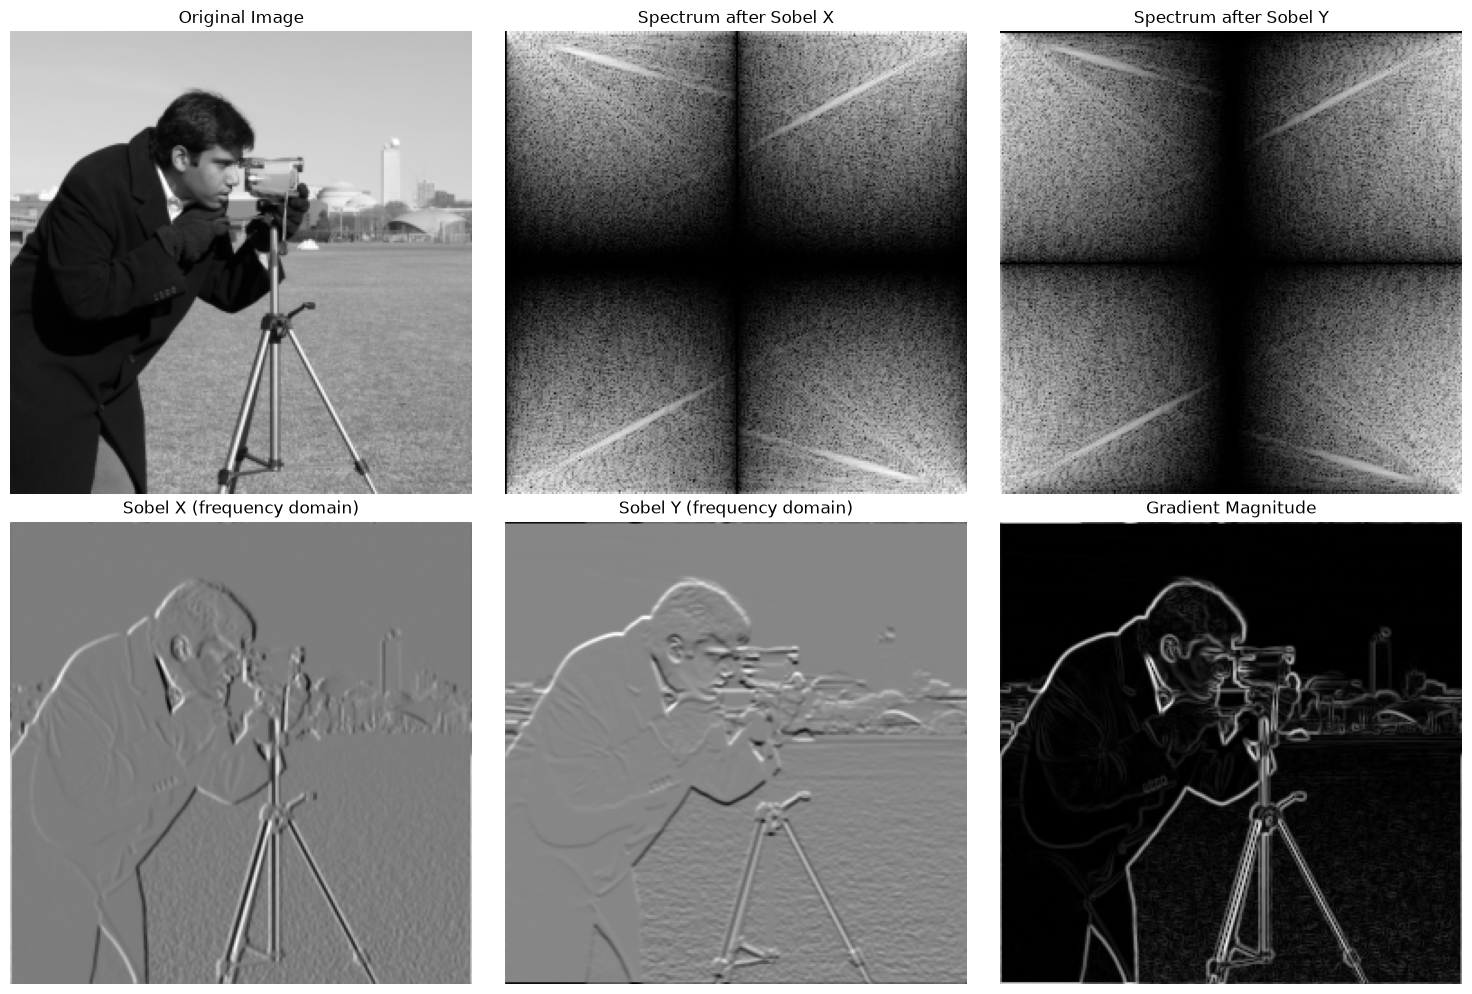

In [2]:
from numpy.fft import fft2, ifft2, ifftshift

# Load and resize image
image = resize(data.camera(), (256, 256))

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # shift so (0,0) is top-left

# FFT of image
F = fft2(image)

# FFT of centered Sobel filters
Hx = center_embed_kernel(sobel_x, image.shape)
Hy = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain and go back to spatial
gx = ifft2(F * Hx).real
gy = ifft2(F * Hy).real
magnitude = np.sqrt(gx**2 + gy**2)

fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax[0, 0].imshow(image, cmap='gray'); ax[0, 0].set_title("Original Image")
ax[0, 1].imshow(np.log(1 + np.abs(F * Hx)), cmap='gray'); ax[0, 1].set_title("Spectrum after Sobel X")
ax[0, 2].imshow(np.log(1 + np.abs(F * Hy)), cmap='gray'); ax[0, 2].set_title("Spectrum after Sobel Y")
ax[1, 0].imshow(gx, cmap='gray'); ax[1, 0].set_title("Sobel X (frequency domain)")
ax[1, 1].imshow(gy, cmap='gray'); ax[1, 1].set_title("Sobel Y (frequency domain)")
ax[1, 2].imshow(magnitude, cmap='gray'); ax[1, 2].set_title("Gradient Magnitude")
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

Sobel X picks out the vertical edges (the tripod legs and the sides of the buildings) and Sobel Y picks out the horizontal ones. The magnitude combines both, so all the edges of the man and the buildings show up. Multiplying the FFTs is a circular convolution, so there can be a little wrap-around at the image borders.